In [1]:
import numpy as np
import cv2
import PIL.Image as Image
import os
import matplotlib.pylab as plt
import tensorflow as tf
import tensorflow_hub as hub
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [2]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

IMAGE_SHAPE = (224, 224)

base_model = MobileNetV2(
    input_shape=IMAGE_SHAPE + (3,),
    include_top=True,
    weights="imagenet"
)

classifier = models.Model(
    inputs=base_model.input,
    outputs=base_model.output
)

classifier.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 3,538,984 (13.50 MB)

 Trainable params: 3,504,872 (13.37 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [3]:
#using this we successfully imported a pre trained model and now we need to use the same model for classification of a similar type of dataset or data sample

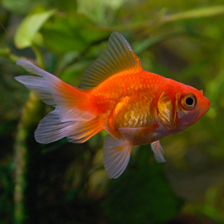

In [4]:
IMAGE_SHAPE = (224, 224)
gold_fish = Image.open ('goldfish.jpg').resize(IMAGE_SHAPE)
gold_fish


In [5]:
gold_fish = np.array(gold_fish)/255.0
gold_fish.shape

(224, 224, 3)

In [6]:
#for multiple image prediction at once we will be using
gold_fish[np.newaxis,...].shape
#this adds a new dimension which marks the image count


(1, 224, 224, 3)

In [15]:
result = classifier.predict(gold_fish[np.newaxis, ...])
result
#this predicts individual values of prediction
#the shape of this also give 1001 which is the no. of classes present in the dataset classification

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


array([[4.34488786e-04, 9.68138695e-01, 1.41548844e-05, 1.32459345e-05,
        2.13224012e-05, 1.02870566e-04, 1.14342592e-05, 2.74572867e-05,
        8.43370362e-05, 2.56279691e-06, 1.77490729e-05, 2.35570878e-05,
        3.36789926e-05, 1.47052660e-05, 1.39960066e-05, 1.48091167e-05,
        4.06990730e-05, 1.01206324e-05, 1.25488468e-05, 4.97061865e-06,
        8.85435202e-06, 1.92209227e-05, 1.28069723e-05, 2.08953952e-05,
        6.63831452e-05, 2.34618237e-05, 6.67058484e-05, 4.45504083e-05,
        1.49139823e-05, 1.30075059e-04, 4.35480870e-05, 1.66023092e-05,
        4.62427743e-05, 1.76062036e-04, 7.45121215e-05, 1.68958955e-04,
        2.01218791e-04, 1.00867968e-04, 1.37551233e-05, 1.53811670e-05,
        8.93344532e-06, 2.15194941e-05, 8.25087845e-05, 2.47377902e-05,
        7.98155452e-06, 1.70652911e-05, 1.62640881e-05, 5.95574747e-05,
        7.67584424e-06, 6.62678667e-06, 5.17270337e-06, 1.17589138e-04,
        1.29600621e-05, 2.05150591e-05, 1.70908770e-05, 9.828187

In [11]:
predicted_label_index = np.argmax(result)
predicted_label_index

np.int64(1)

In [12]:
image_labels=[]
with open("datasets/ImageNetLabels.txt") as f:
    image_labels= f.read().splitlines()
image_labels[:10]

['background',
 'tench',
 'goldfish',
 'great white shark',
 'tiger shark',
 'hammerhead',
 'electric ray',
 'stingray',
 'cock',
 'hen']

In [40]:
data_dir = tf.keras.utils.get_file('flower_photos', origin="datasets", cache_dir='.', untar=True)
data_dir

ValueError: unknown url type: 'datasets'

In [31]:
#this changes the path to windows path for each image or sample using pre defined lib of python called pathlib
import pathlib
data_dir = pathlib.Path(data_dir)
data_dir

PosixPath('datasets/flower_photos')

In [33]:
list(data_dir.glob('*/*.jpg'))[:5]

[]

In [36]:
image_count = len(list(data_dir.glob('*/*-jpg')))
print(image_count)

0
